# 01 — EDA et contrôle qualité des données
### Mini-projet : Classification du Score de Crédit — Groupe RSD10

**But de cette phase :** comprendre les 100 000 observations et les 28 attributs, étudier les classes, les valeurs manquantes, les anomalies, les distributions, les variables catégorielles, les corrélations et réaliser **deux tests statistiques justifiés**.

**Important :** ce notebook n'écrase jamais `data/raw/train.csv`. Les corrections de formats sont faites **en mémoire**, dans `df_eda`, uniquement pour rendre les analyses possibles. L'imputation et le prétraitement définitif seront réalisés plus tard, *après* la séparation entraînement/test pour éviter les fuites de données.

**Exécution :** ouvrir ce notebook dans VS Code, sélectionner le kernel `.venv`, puis cliquer sur **Run All**. En cas d'erreur d'import, installer les bibliothèques indiquées dans la réponse ChatGPT.

## 1. Charger le dataset
Nous recherchons le CSV à partir du dossier racine ou du dossier `notebooks/`. Nous n'affichons pas les colonnes contenant des informations personnelles (`Name`, `SSN`).

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

possibilites = [
    Path.cwd() / "data" / "raw" / "train.csv",
    Path.cwd().parent / "data" / "raw" / "train.csv",
]
chemin = next((p for p in possibilites if p.is_file()), None)
if chemin is None:
    raise FileNotFoundError(
        "Fichier train.csv introuvable. Vérifie qu'il est dans data/raw/ "
        "et que ton notebook est ouvert depuis le projet."
    )

df = pd.read_csv(chemin, low_memory=False)
print(f"Fichier : {chemin.resolve()}")
print(f"Dimensions : {df.shape[0]:,} lignes × {df.shape[1]} colonnes")
print("Colonnes :", list(df.columns))
colonnes_publiques = ["Age", "Annual_Income", "Outstanding_Debt", "Credit_Score"]
display(df[[c for c in colonnes_publiques if c in df.columns]].head())

Fichier : C:\Users\user\Desktop\projetdatamin\mini-projet-data-mining\data\raw\train.csv
Dimensions : 100,000 lignes × 28 colonnes
Colonnes : ['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance', 'Credit_Score']


,Age,Annual_Income,Outstanding_Debt,Credit_Score
0,23,19114.12,809.98,Good
1,23,19114.12,809.98,Good
2,-500,19114.12,809.98,Good
3,23,19114.12,809.98,Good
4,23,19114.12,809.98,Good


## 2. Structure, doublons et clients répétés
**Attention :** plusieurs lignes peuvent représenter le **même client** à des mois différents. Une future division aléatoire ligne par ligne pourrait mettre un même client dans l'entraînement et le test, créant une fuite d'information.

In [14]:
print("Types des colonnes :")
display(df.dtypes.rename("type").to_frame())
print("Lignes strictement identiques :", int(df.duplicated().sum()))
if "Customer_ID" in df.columns:
    freq_clients = df["Customer_ID"].value_counts(dropna=True)
    print("Nombre de clients distincts :", df["Customer_ID"].nunique())
    print("Observations par client (min / médiane / max) :",
          int(freq_clients.min()), float(freq_clients.median()), int(freq_clients.max()))
else:
    print("Attention : colonne Customer_ID absente")

Types des colonnes :


,type
ID,str
Customer_ID,str
Month,str
Name,str
Age,str
SSN,str
Occupation,str
Annual_Income,str
Monthly_Inhand_Salary,float64
Num_Bank_Accounts,int64


Lignes strictement identiques : 0
Nombre de clients distincts : 12500
Observations par client (min / médiane / max) : 8 8.0 8


## 3. Répartition de la variable cible `Credit_Score`
Cette analyse montre le déséquilibre éventuel des classes. Une classe majoritaire rend **l'accuracy seule insuffisante** pour juger un modèle.

,effectif,pourcentage
Credit_Score,,
Standard,53174,53.17
Poor,28998,29.00
Good,17828,17.83


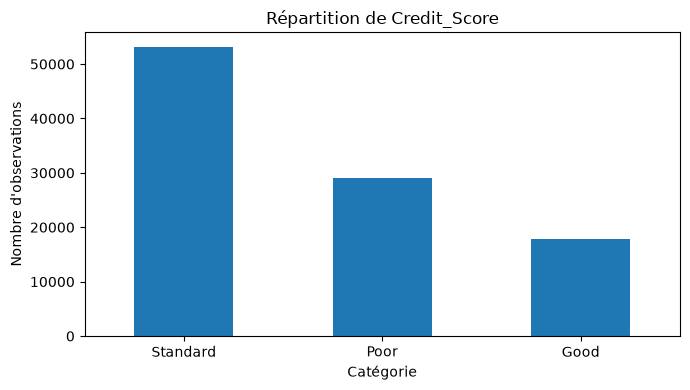

In [15]:
cible = "Credit_Score"
if cible not in df.columns:
    raise KeyError("La colonne cible Credit_Score est absente")
repartition = df[cible].value_counts(dropna=False)
resultats_cible = pd.DataFrame({
    "effectif": repartition,
    "pourcentage": (repartition / len(df) * 100).round(2)
})
display(resultats_cible)
ax = repartition.plot(kind="bar", figsize=(7, 4), rot=0, title="Répartition de Credit_Score")
ax.set_xlabel("Catégorie")
ax.set_ylabel("Nombre d'observations")
plt.tight_layout()
plt.show()

## 4. Valeurs manquantes brutes
Nous comptons les `NaN` mais aussi les chaînes vides. Les valeurs symboliques telles que `_`, `_______`, `!@9#%8` seront ensuite considérées séparément.

In [16]:
vides = df.isna().copy()
for col in df.select_dtypes(include=["object", "string"]).columns:
    vides[col] = vides[col] | df[col].astype("string").str.strip().eq("").fillna(False)

manquants_bruts = pd.DataFrame({
    "vides": vides.sum().astype(int),
    "pourcentage": (vides.mean() * 100).round(2)
}).sort_values("vides", ascending=False)
display(manquants_bruts.loc[manquants_bruts["vides"] > 0])

,vides,pourcentage
Monthly_Inhand_Salary,15002,15.0
Type_of_Loan,11408,11.41
Name,9985,9.98
Credit_History_Age,9030,9.03
Num_of_Delayed_Payment,7002,7.0
Amount_invested_monthly,4479,4.48
Num_Credit_Inquiries,1965,1.96
Monthly_Balance,1200,1.2


## 5. Vérifier les codes d'erreur connus
Ce comptage sert à documenter les anomalies **avant** toute conversion. Le caractère `_` final dans certaines colonnes numériques correspond souvent à un problème de format récupérable ; `_` ou `!@9#%8` seuls signifient une information inconnue.

In [17]:
numeriques = [
    "Age", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts",
    "Num_Credit_Card", "Interest_Rate", "Num_of_Loan", "Delay_from_due_date",
    "Num_of_Delayed_Payment", "Changed_Credit_Limit", "Num_Credit_Inquiries",
    "Outstanding_Debt", "Credit_Utilization_Ratio", "Total_EMI_per_month",
    "Amount_invested_monthly", "Monthly_Balance"
]
numeriques = [col for col in numeriques if col in df.columns]

bilan_codes = []
for col in ["Age", "Annual_Income", "Num_of_Loan", "Outstanding_Debt", "Credit_Mix", "Payment_Behaviour", "Occupation"]:
    if col not in df.columns:
        continue
    serie = df[col].astype("string").str.strip()
    compte = int((serie.str.endswith("_").fillna(False)).sum())
    marques = int(serie.isin(["_", "_______", "!@9#%8"]).sum())
    bilan_codes.append({"colonne": col, "finit_par_underscore": compte,
                        "marqueur_inconnu": marques})
display(pd.DataFrame(bilan_codes))

,colonne,finit_par_underscore,marqueur_inconnu
0,Age,4939,0
1,Annual_Income,6980,0
2,Num_of_Loan,4785,0
3,Outstanding_Debt,1009,0
4,Credit_Mix,20195,20195
5,Payment_Behaviour,0,7600
6,Occupation,7062,7062


## 6. Copie de travail pour l'exploration
On conserve `df` **brut**. On crée `df_eda` et on effectue seulement une **harmonisation de formats** : retirer les `_` de fin pour les nombres convertibles ; convertir les codes d'absence explicites en `NaN`.

**Ne pas confondre avec le pipeline d'entraînement :** les valeurs aberrantes (par exemple `Age=-500`) ne sont pas corrigées ici. Les futures imputations et transformations statistiques devront être ajustées sur les données d'entraînement uniquement.

In [18]:
df_eda = df.copy()

def nombre_depuis_texte(serie):
    texte = serie.astype("string").str.strip()
    texte = texte.str.replace(r"_+$", "", regex=True)
    texte = texte.replace({"": pd.NA, "!@9#%8": pd.NA})
    return pd.to_numeric(texte, errors="coerce")

for col in numeriques:
    df_eda[col] = nombre_depuis_texte(df[col])

categoriels = [
    "Month", "Occupation", "Type_of_Loan", "Credit_Mix",
    "Payment_of_Min_Amount", "Payment_Behaviour", "Credit_History_Age"
]
for col in categoriels:
    if col in df_eda.columns:
        df_eda[col] = df_eda[col].astype("string").str.strip().replace({
            "": pd.NA, "_": pd.NA, "_______": pd.NA, "!@9#%8": pd.NA
        })

print("Copie exploratoire créée. Dataset brut intact :", df.shape == df_eda.shape)
print("Colonnes numériques reconnues :", len(numeriques))

Copie exploratoire créée. Dataset brut intact : True
Colonnes numériques reconnues : 16


## 7. Valeurs manquantes après conversion des formats
Les conversions peuvent révéler de nouvelles valeurs non numériques. Cela ne remplace pas le diagnostic initial : il s'agit ici des valeurs absentes **ou non convertibles** dans la copie exploratoire.

,nombre,pourcentage
Credit_Mix,20195,20.20
Monthly_Inhand_Salary,15002,15.00
Type_of_Loan,11408,11.41
Name,9985,9.98
Credit_History_Age,9030,9.03
Amount_invested_monthly,8784,8.78
Payment_Behaviour,7600,7.60
Occupation,7062,7.06
Num_of_Delayed_Payment,7002,7.00
Changed_Credit_Limit,2091,2.09


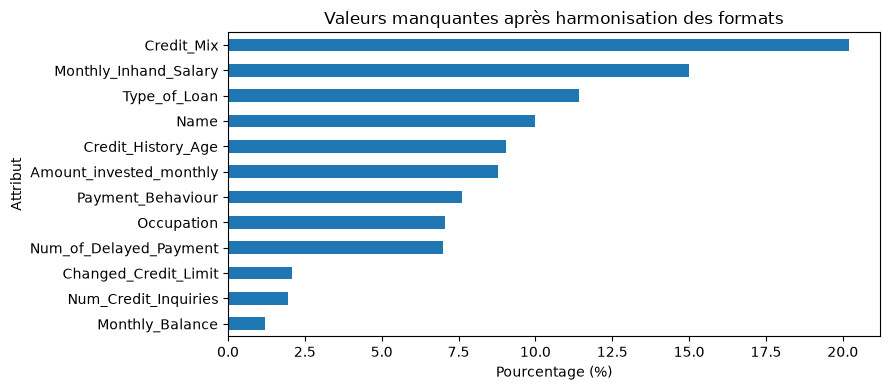

In [19]:
table_manquants = pd.DataFrame({
    "nombre": df_eda.isna().sum().astype(int),
    "pourcentage": (df_eda.isna().mean() * 100).round(2)
}).sort_values("nombre", ascending=False)
display(table_manquants[table_manquants["nombre"] > 0])

à_tracer = table_manquants[table_manquants["nombre"] > 0].sort_values("pourcentage")
if not à_tracer.empty:
    ax = à_tracer["pourcentage"].plot.barh(figsize=(9, max(4, len(à_tracer) * 0.32)))
    ax.set_title("Valeurs manquantes après harmonisation des formats")
    ax.set_xlabel("Pourcentage (%)")
    ax.set_ylabel("Attribut")
    plt.tight_layout()
    plt.show()

## 8. Statistiques descriptives et extrêmes
Tableau des principales mesures de tendance centrale et de dispersion : moyenne, médiane, écart-type, minimum, maximum et quantiles. Les extrêmes ne sont **pas automatiquement** des erreurs.

In [20]:
statistiques = df_eda[numeriques].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
statistiques = statistiques.rename(columns={"50%": "mediane"})
display(statistiques.round(2))

# Seuils provisoires, uniquement pour détecter des cas à examiner
age = df_eda["Age"]
prets = df_eda["Num_of_Loan"]
controle = pd.DataFrame([
    {"controle": "Age <= 0", "effectif": int((age <= 0).sum())},
    {"controle": "Age > 120", "effectif": int((age > 120).sum())},
    {"controle": "Num_of_Loan < 0", "effectif": int((prets < 0).sum())},
    {"controle": "Num_of_Loan > 100 (seuil exploratoire)",
     "effectif": int((prets > 100).sum())},
])
display(controle)
print("Les anomalies sont signalées, pas supprimées.")

,count,mean,std,min,1%,25%,mediane,75%,99%,max
Age,100000.0,110.65,686.24,-500.0,14.0,24.0,33.0,42.0,4112.07,8698.0
Annual_Income,100000.0,176415.7,1429618.05,7005.93,7536.0,19457.5,37578.61,72790.92,179987.28,24198062.0
Monthly_Inhand_Salary,84998.0,4194.17,3183.69,303.65,531.88,1625.57,3093.75,5957.45,13814.93,15204.63
Num_Bank_Accounts,100000.0,17.09,117.4,-1.0,0.0,3.0,6.0,7.0,445.01,1798.0
Num_Credit_Card,100000.0,22.47,129.06,0.0,1.0,4.0,5.0,7.0,849.0,1499.0
Interest_Rate,100000.0,72.47,466.42,1.0,1.0,8.0,13.0,20.0,2865.01,5797.0
Num_of_Loan,100000.0,3.01,62.65,-100.0,-100.0,1.0,3.0,5.0,9.0,1496.0
Delay_from_due_date,100000.0,21.07,14.86,-5.0,0.0,10.0,18.0,28.0,61.0,67.0
Num_of_Delayed_Payment,92998.0,30.92,226.03,-3.0,0.0,9.0,14.0,18.0,27.0,4397.0
Changed_Credit_Limit,97909.0,10.39,6.79,-6.49,-1.54,5.32,9.4,14.87,28.81,36.97


,controle,effectif
0,Age <= 0,886
1,Age > 120,1884
2,Num_of_Loan < 0,3876
3,Num_of_Loan > 100 (seuil exploratoire),437


Les anomalies sont signalées, pas supprimées.


## 9. Distributions numériques : histogrammes et densités KDE
Pour rendre les graphiques lisibles, on affiche uniquement les observations comprises entre les quantiles 1 % et 99 % **dans la figure** ; les données d'origine ne sont ni filtrées ni supprimées. On écarte aussi les âges invraisemblables des **graphiques d'âge uniquement**.

La courbe KDE est une estimation lissée de la distribution ; elle sert à la description, pas à la prédiction.

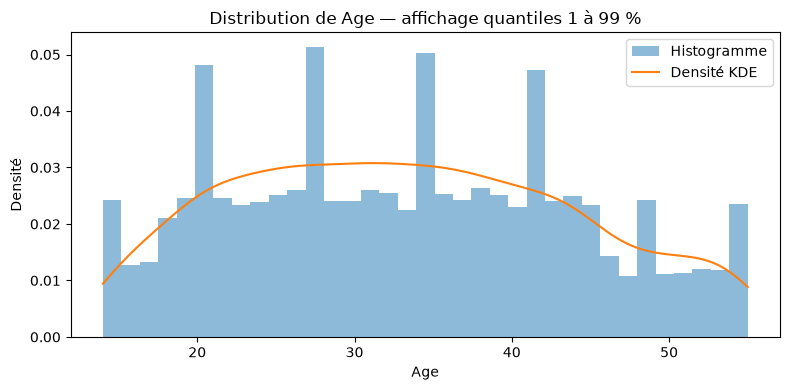

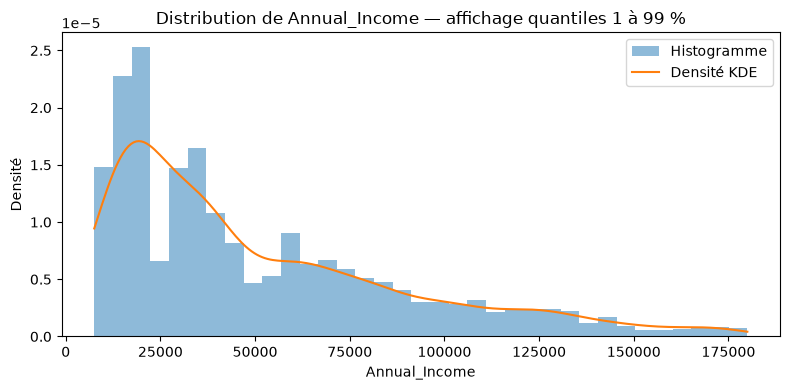

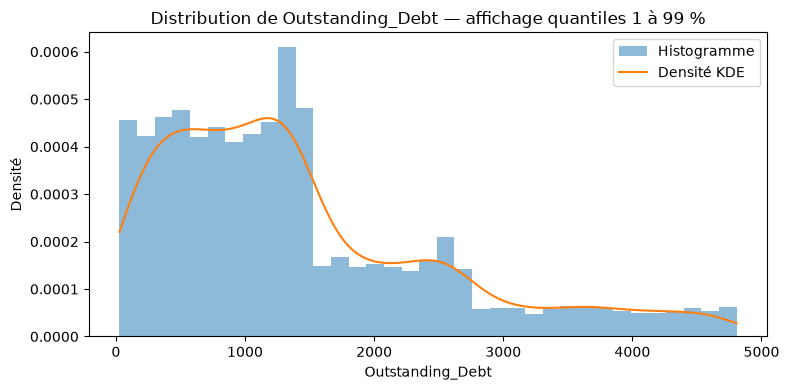

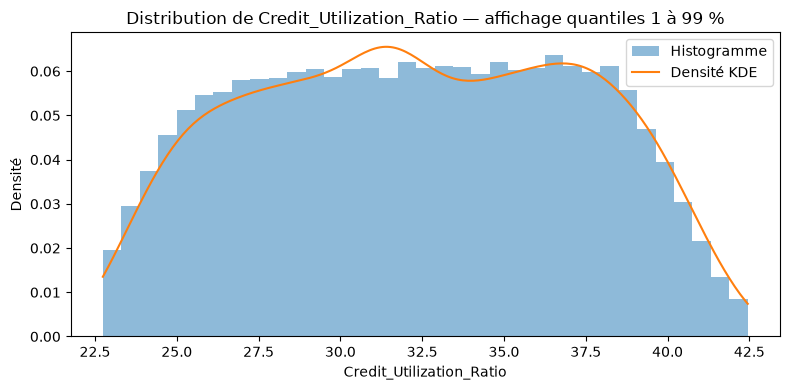

In [21]:
colonnes_graphique = ["Age", "Annual_Income", "Outstanding_Debt", "Credit_Utilization_Ratio"]
for col in colonnes_graphique:
    if col not in df_eda.columns:
        continue
    valeurs = df_eda[col].dropna().astype(float)
    valeurs = valeurs[np.isfinite(valeurs)]
    if col == "Age":
        valeurs = valeurs[valeurs.between(1, 120)]
    if len(valeurs) < 20:
        continue
    q1, q99 = valeurs.quantile([0.01, 0.99])
    v = valeurs[valeurs.between(q1, q99)]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(v, bins=35, density=True, alpha=0.5, label="Histogramme")
    echantillon = v.sample(n=min(3000, len(v)), random_state=42)
    if echantillon.nunique() > 1:
        estimation = stats.gaussian_kde(echantillon.to_numpy())
        x = np.linspace(float(v.min()), float(v.max()), 250)
        ax.plot(x, estimation(x), label="Densité KDE")
    ax.set_title(f"Distribution de {col} — affichage quantiles 1 à 99 %")
    ax.set_xlabel(col)
    ax.set_ylabel("Densité")
    ax.legend()
    plt.tight_layout()
    plt.show()

## 10. Distributions des variables catégorielles
Les identifiants (`ID`, `Customer_ID`, `SSN`, `Name`) ne sont **pas** utilisés comme variables explicatives ni exposés dans les résultats publics. On visualise quelques variables métiers pertinentes.

,Credit_Mix : effectif
Credit_Mix,
Standard,36479
Good,24337
[Manquant],20195
Bad,18989


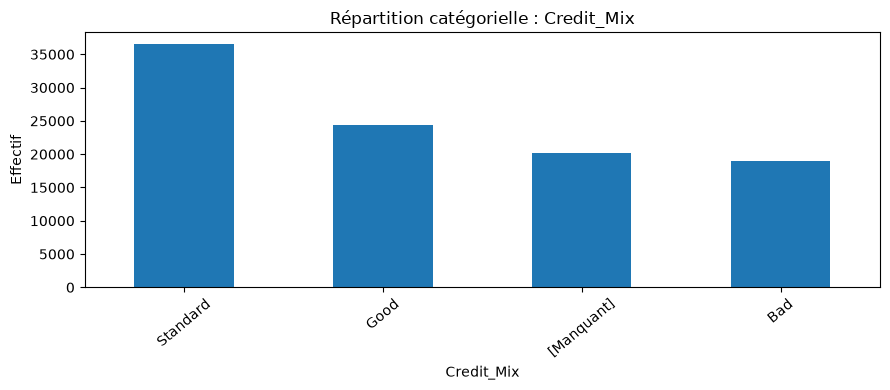

,Occupation : effectif
Occupation,
[Manquant],7062
Lawyer,6575
Architect,6355
Engineer,6350
Scientist,6299
Mechanic,6291
Accountant,6271
Developer,6235
Media_Manager,6232


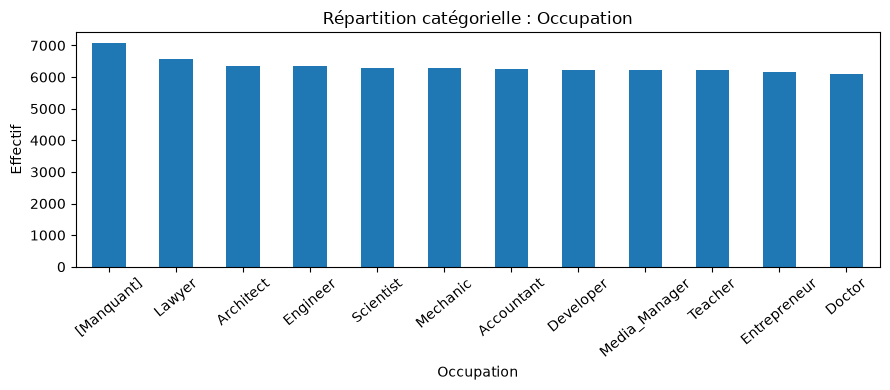

,Payment_Behaviour : effectif
Payment_Behaviour,
Low_spent_Small_value_payments,25513
High_spent_Medium_value_payments,17540
Low_spent_Medium_value_payments,13861
High_spent_Large_value_payments,13721
High_spent_Small_value_payments,11340
Low_spent_Large_value_payments,10425
[Manquant],7600


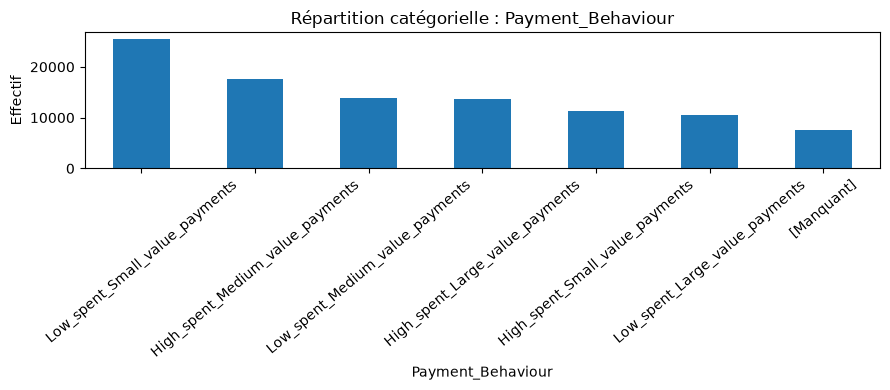

,Payment_of_Min_Amount : effectif
Payment_of_Min_Amount,
Yes,52326
No,35667
NM,12007


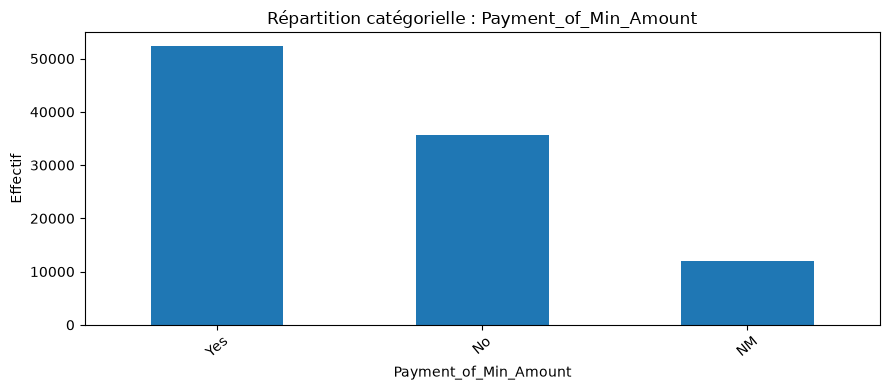

In [22]:
colonnes_categories = ["Credit_Mix", "Occupation", "Payment_Behaviour", "Payment_of_Min_Amount"]
for col in colonnes_categories:
    if col not in df_eda.columns:
        continue
    frequences = df_eda[col].fillna("[Manquant]").value_counts().head(12)
    display(frequences.rename(f"{col} : effectif").to_frame())
    fig, ax = plt.subplots(figsize=(9, 4))
    frequences.plot.bar(ax=ax, rot=40)
    ax.set_title(f"Répartition catégorielle : {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Effectif")
    plt.tight_layout()
    plt.show()

## 11. Corrélations numériques (Pearson)
La corrélation mesure une association **linéaire**, et non une causalité. Le score à prédire est une **catégorie** et ne doit pas être encodé arbitrairement en 0, 1, 2 pour calculer une corrélation de Pearson.

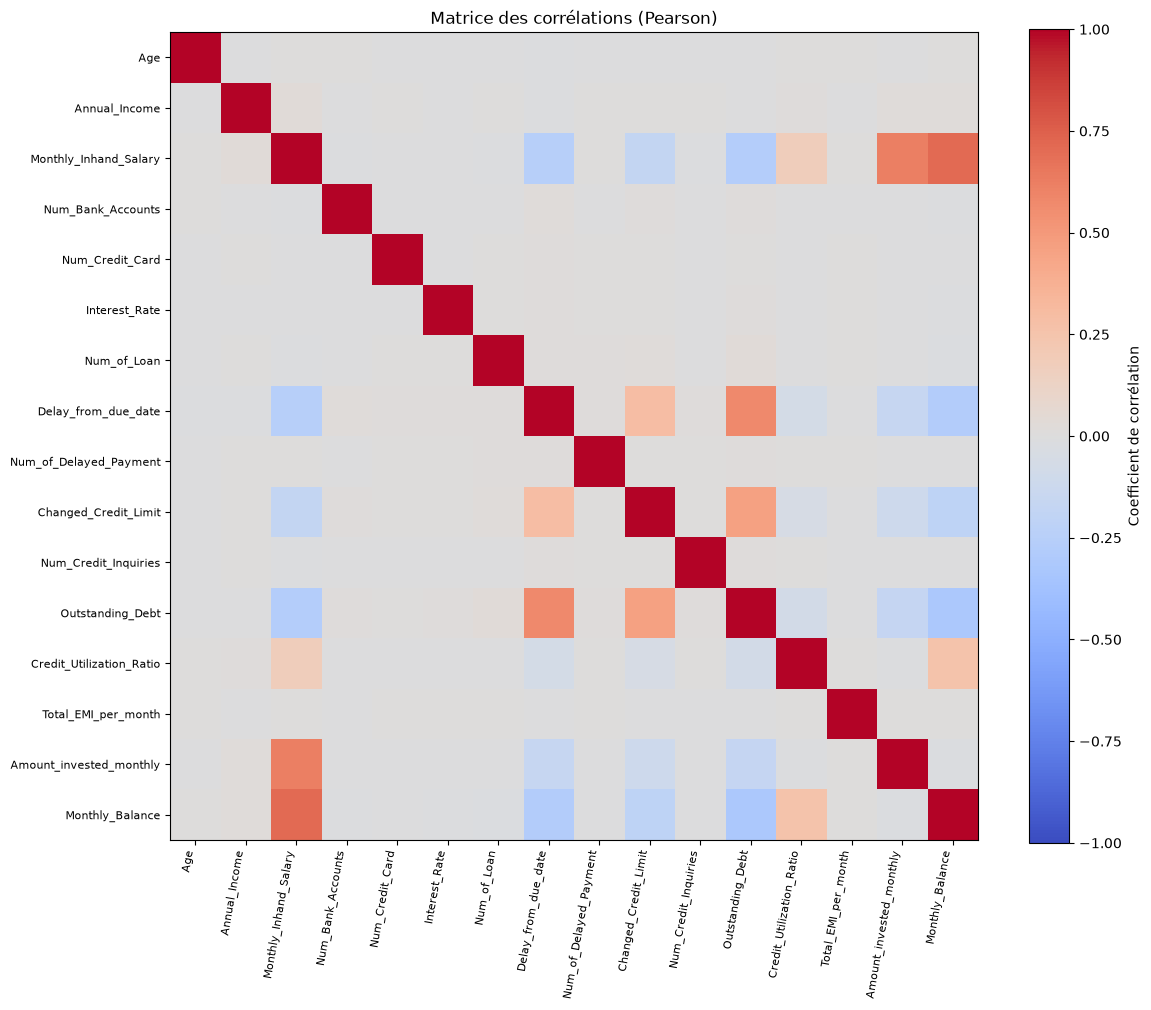

10 associations linéaires les plus fortes (en valeur absolue) :


corrélation
Monthly_Inhand_Salary    Monthly_Balance             0.704849
                         Amount_invested_monthly     0.623106
Delay_from_due_date      Outstanding_Debt            0.571713
Changed_Credit_Limit     Outstanding_Debt            0.458549
Outstanding_Debt         Monthly_Balance            -0.314758
Delay_from_due_date      Changed_Credit_Limit        0.293697
                         Monthly_Balance            -0.279068
Monthly_Inhand_Salary    Outstanding_Debt           -0.269727
Credit_Utilization_Ratio Monthly_Balance             0.251486
Monthly_Inhand_Salary    Delay_from_due_date        -0.250100

In [23]:
correlations = df_eda[numeriques].corr(method="pearson")
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(correlations.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlations.columns)), correlations.columns, rotation=80, ha="right", fontsize=8)
ax.set_yticks(range(len(correlations.index)), correlations.index, fontsize=8)
ax.set_title("Matrice des corrélations (Pearson)")
fig.colorbar(image, ax=ax, label="Coefficient de corrélation")
plt.tight_layout()
plt.show()

# Couples associés les plus fortement en valeur absolue (hors diagonale)
haut = correlations.where(np.triu(np.ones(correlations.shape), k=1).astype(bool))
paires = haut.stack().sort_values(key=lambda s: s.abs(), ascending=False)
print("10 associations linéaires les plus fortes (en valeur absolue) :")
display(paires.head(10).rename("corrélation").to_frame())

## 12. Deux tests statistiques justifiés 

**Pourquoi sélectionner un seul enregistrement par client pour les tests ?** Les données comprennent plusieurs mois pour un même `Customer_ID`. Prendre toutes les lignes comme observations indépendantes fausserait les hypothèses classiques de ces tests. Nous utilisons ici *un enregistrement aléatoire reproductible par client*. Cela atténue la dépendance sans prétendre à une indépendance parfaite.

- **Test 1 — χ² d'indépendance :** `Credit_Mix` et `Credit_Score` sont deux variables catégorielles. **H₀ :** aucune association entre les catégories. On vérifie aussi les effectifs attendus.
- **Test 2 — Kruskal–Wallis :** `Outstanding_Debt` est numérique, et `Credit_Score` définit trois groupes. On privilégie un test non paramétrique, car la dette peut être asymétrique. **H₀ :** mêmes distributions de dettes entre les groupes.

**Interprétation :** `p < 0,05` suggère une association/différence statistique, mais ne mesure pas sa taille ni une relation causale. Les tests sont exploratoires ; ce ne sont pas des preuves de performance prédictive.

In [24]:
if "Customer_ID" not in df_eda.columns:
    raise KeyError("Customer_ID nécessaire pour limiter les observations répétées par client")

echantillon_clients = (
    df_eda.sample(frac=1, random_state=42)
          .drop_duplicates(subset="Customer_ID")
          .copy()
)
print("Nombre de clients dans les tests :", len(echantillon_clients))

# Test 1 — Khi-deux
contingence = pd.crosstab(echantillon_clients["Credit_Mix"],
                         echantillon_clients["Credit_Score"])
if contingence.shape[0] < 2 or contingence.shape[1] < 2:
    print("Test χ² impossible : catégories insuffisantes")
else:
    chi2, p_chi2, ddl, attendus = stats.chi2_contingency(contingence)
    n = contingence.to_numpy().sum()
    v_cramer = np.sqrt((chi2 / n) / min(contingence.shape[0]-1, contingence.shape[1]-1))
    print("\nTEST 1 : χ² (Credit_Mix × Credit_Score)")
    print(f"χ² = {chi2:.3f} | ddl = {ddl} | p = {p_chi2:.3g} | V de Cramér = {v_cramer:.3f}")
    print("Effectif attendu minimum :", round(float(attendus.min()), 2))
    if (attendus < 5).any():
        print("ATTENTION : certaines cases ont un effectif attendu < 5 ; vérifier la validité du test.")
    display(contingence)

# Test 2 — Kruskal-Wallis
sous_ensemble = echantillon_clients[["Outstanding_Debt", "Credit_Score"]].dropna()
classes = [x for x in ["Good", "Standard", "Poor"] if x in sous_ensemble["Credit_Score"].unique()]
groupes = [sous_ensemble.loc[sous_ensemble["Credit_Score"].eq(x), "Outstanding_Debt"].astype(float).to_numpy()
           for x in classes]
print("\nTEST 2 : Kruskal–Wallis (Outstanding_Debt selon Credit_Score)")
if len(groupes) >= 2 and all(len(g) > 0 for g in groupes):
    h, p_kw = stats.kruskal(*groupes)
    print(f"H = {h:.3f} | p = {p_kw:.3g}")
    display(sous_ensemble.groupby("Credit_Score")["Outstanding_Debt"].agg(["count", "median", "mean"]).round(2))
else:
    print("Nombre de groupes insuffisant pour le test")

Nombre de clients dans les tests : 12500

TEST 1 : χ² (Credit_Mix × Credit_Score)
χ² = 4064.985 | ddl = 4 | p = 0 | V de Cramér = 0.450
Effectif attendu minimum : 428.9


Credit_Score,Good,Poor,Standard
Credit_Mix,,,
Bad,32,1431,953
Good,1497,475,1074
Standard,256,1006,3331



TEST 2 : Kruskal–Wallis (Outstanding_Debt selon Credit_Score)
H = 2411.793 | p = 0


,count,median,mean
Credit_Score,,,
Good,2246,732.22,792.28
Poor,3655,1933.38,2073.38
Standard,6599,1005.37,1283.54


## 13. Synthèse de l'EDA et décisions pour la suite

### 13.1. Description du jeu de données

Le dataset *Credit Score Classification* comprend 100 000 observations et 28 attributs. La variable cible `Credit_Score` possède trois classes : Standard (53,17 %), Poor (29,00 %) et Good (17,83 %).

Cette répartition montre un déséquilibre des classes, qui devra être pris en compte lors de l'évaluation des modèles.

### 13.2. Qualité des données

L'analyse a révélé plusieurs problèmes de qualité :

- Sept colonnes contiennent des cellules vides, notamment `Monthly_Inhand_Salary` (15 %).
- `Credit_Mix` contient 20 195 valeurs représentées par `_`.
- `Payment_Behaviour` contient 7 600 valeurs invalides représentées par `!@9#%8`.
- La colonne `Age` présente 2 770 valeurs suspectes selon les seuils exploratoires retenus.
- La colonne `Num_of_Loan` présente 4 313 valeurs suspectes.

Certaines anomalies de format sont récupérables en supprimant les caractères `_` placés à la fin des valeurs numériques.

### 13.3. Distributions et corrélations

Les distributions mettent en évidence une asymétrie positive des revenus annuels et des dettes, ainsi que des concentrations particulières dans certaines variables.

L'analyse des corrélations de Pearson révèle notamment :

- Une corrélation positive entre `Monthly_Inhand_Salary` et `Monthly_Balance` (r = 0,705).
- Une corrélation positive entre `Delay_from_due_date` et `Outstanding_Debt` (r = 0,572).

Ces associations sont descriptives et ne démontrent pas de relations causales. Les valeurs aberrantes devront également être prises en compte dans leur interprétation.

### 13.4. Tests statistiques

Le test du Khi-deux met en évidence une association statistiquement significative entre `Credit_Mix` et `Credit_Score` (χ² = 4064,985 ; p < 0,001 ; V de Cramér = 0,450).

Le test de Kruskal–Wallis indique que les distributions de `Outstanding_Debt` diffèrent significativement selon les catégories de crédit (H = 2411,793 ; p < 0,001).

Pour limiter la dépendance liée aux observations mensuelles répétées, ces tests ont été réalisés sur un échantillon de 12 500 clients distincts, avec un enregistrement sélectionné par client.

### 13.5. Décisions pour le prétraitement

La phase suivante devra :

1. Corriger les formats numériques récupérables.
2. Traiter les valeurs manquantes et les valeurs aberrantes.
3. Préparer les variables numériques et catégorielles.
4. Exclure les identifiants personnels des variables prédictives.
5. Séparer les données d'entraînement et de test par `Customer_ID` afin de réduire les risques de fuite de données.
6. Ajuster les transformations statistiques uniquement sur les données d'entraînement.

### Conclusion

L'analyse exploratoire a permis d'identifier les principales caractéristiques et les problèmes de qualité du jeu de données. Les résultats montrent l'importance des variables financières dans l'étude du score de crédit et justifient la mise en place d'un prétraitement rigoureux avant l'entraînement des modèles de classification.